# LINEBENCH — Phase 0 Toolchain & Instance Exploration

This notebook verifies the toolchain setup for Phase 0:
1. Loads the Bowman-8 classical instance.
2. Computes theoretical lower bounds $LB_1$ and $LB_2$.
3. Constructs the NetworkX precedence DAG and visualizes it.
4. Solves with the prototype OR-Tools CP-SAT model.

In [1]:
import math
import networkx as nx
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, '../src')

from linebench.exact.prototype import solve_salbp1_prototype

In [2]:
# Load Bowman-8 parameters
tasks = list(range(1, 9))
task_times = [11, 17, 9, 5, 8, 12, 10, 3]
precedences = [
    (1, 2), (2, 3), (2, 4), (3, 5), (3, 6), (4, 6), (5, 7), (6, 8)
]
cycle_time = 20

# Compute Lower Bounds
sum_t = sum(task_times)
lb1 = math.ceil(sum_t / cycle_time)
strictly_greater = sum(1 for t in task_times if t > cycle_time / 2)
equal_half = sum(1 for t in task_times if t == cycle_time / 2)
lb2 = strictly_greater + math.ceil(equal_half / 2)
lb = max(lb1, lb2)

print(f"Total Work Content: {sum_t}")
print(f"Cycle Time: {cycle_time}")
print(f"LB1 (Total Work Content): {lb1}")
print(f"LB2 (Half-Cycle Tasks): {lb2}")
print(f"Combined Lower Bound LB: {lb}")

Total Work Content: 75
Cycle Time: 20
LB1 (Total Work Content): 4
LB2 (Half-Cycle Tasks): 4
Combined Lower Bound LB: 4


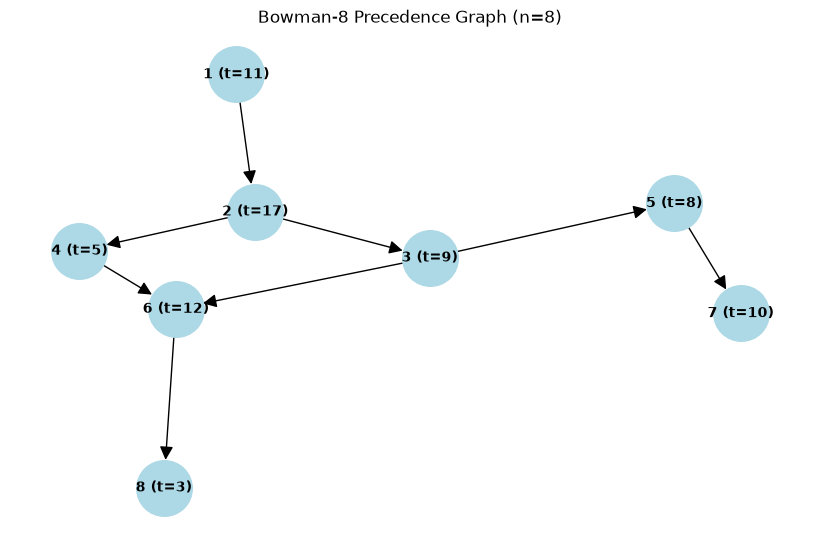

In [3]:
# Construct Precedence Graph
G = nx.DiGraph()
for i, t in enumerate(task_times, start=1):
    G.add_node(i, time=t, label=f"{i} (t={t})")
G.add_edges_from(precedences)

# Draw Graph
pos = nx.spring_layout(G, seed=42)
labels = nx.get_node_attributes(G, 'label')
plt.figure(figsize=(8, 5))
nx.draw(G, pos, with_labels=True, labels=labels, node_color='lightblue', 
        node_size=1600, font_size=10, font_weight='bold', arrowsize=20)
plt.title("Bowman-8 Precedence Graph (n=8)")
plt.show()

In [4]:
# Solve with CP-SAT Prototype
prec_zero_indexed = [(u - 1, v - 1) for u, v in precedences]
res = solve_salbp1_prototype(task_times, prec_zero_indexed, cycle_time, time_limit_seconds=5.0)

print(f"Status: {res['status']}")
print(f"Stations Used: {res['stations_used']} (Known Optimum: 5, LB: {lb})")
for s, assigned in res['assignments'].items():
    station_tasks = [t + 1 for t in assigned]
    load = sum(task_times[t] for t in assigned)
    print(f"  Station {s}: Tasks {station_tasks}, Load = {load}/{cycle_time}")

Status: OPTIMAL
Stations Used: 5 (Known Optimum: 5, LB: 4)
  Station 1: Tasks [1], Load = 11/20
  Station 2: Tasks [2], Load = 17/20
  Station 3: Tasks [3, 5], Load = 17/20
  Station 4: Tasks [4, 7], Load = 15/20
  Station 5: Tasks [6, 8], Load = 15/20
